# UPS and SUPS in the case of the toy gaussian mean shift model:
-    $\pi_\lambda \propto \mathcal{N}(\lambda D, I_d)$ with $D = \alpha \cdot \mathbf{1}_d \in \mathbb{R}^d$ which is the temepring path between $\mathcal{N}(0, I_d)$ and $\mathcal{N}( D, I_d)$

In [1]:
import sys
print(sys.executable)

/Users/b00829592/pathsampling-env/bin/python


In [2]:
import os
import jax
import jax.numpy as jnp
import plotnine as p9

In [3]:

os.environ["ENABLE_PJRT_COMPATIBILITY"] = "1"
os.environ["JAX_PLATFORMS"] = "cpu"


device = jax.devices("cpu")[0]
jax.config.update("jax_default_device", device)

print("JAX version :", jax.__version__)
print("Backend sélectionné :", jax.default_backend())
print("Périphérique par défaut :", device)
print("Périphériques disponibles :", jax.devices())

Platform 'METAL' is experimental and not all JAX functionality may be correctly supported!


Metal device set to: Apple M4 Pro

systemMemory: 24.00 GB
maxCacheSize: 8.88 GB

JAX version : 0.4.26
Backend sélectionné : METAL
Périphérique par défaut : TFRT_CPU_0
Périphériques disponibles : [METAL(id=0)]


W0000 00:00:1795349286.784969   14453 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1795349286.799913   14453 service.cc:145] XLA service 0xb39606600 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795349286.799934   14453 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1795349286.801276   14453 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1795349286.801297   14453 mps_client.cc:384] XLA backend will use up to 19069190144 bytes on device 0 for SimpleAllocator.


In [4]:
import os

os.environ["JAX_PLATFORMS"] = "cpu"
os.environ["OMP_NUM_THREADS"] = "14"
os.environ["MKL_NUM_THREADS"] = "14"
os.environ["XLA_FLAGS"] = (
    "--xla_cpu_multi_thread_eigen=true intra_op_parallelism_threads=14"
)

import jax

In [5]:
from pathlib import Path
import sys

repo_root = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "__init__.py").is_file()
)
sys.path.insert(0, str(repo_root)) if str(repo_root) not in sys.path else None

import src

In [6]:
from src import *

## Plot of the meeting times and tunning of k and m

In [7]:
def log_target0(x):
    return -0.5 * jnp.sum(x**2)


def log_target1(x, D):
    return -0.5 * jnp.sum((x - D)**2)


def g_log_target(x, path, D):
    return (1 - path) * log_target0(x) + path * log_target1(x, D)


def g_grad_log_target(x, D):
    return log_target1(x, D) - log_target0(x)


In [8]:
L = 20  # 0, 0.1, ..., 1.0
lambda_grid = np.arange(0, L + 1) / L # uniform grid of lambda values in [0, 1]

In [9]:
key = jax.random.PRNGKey(42)

d = 2
Sigma = jnp.eye(d) # covaraince of the proposal of RWMH
mean_init = jnp.array([-1.0] * d) # mean for the initial distribution of MH
Sigma_init = jnp.eye(d) # covariance of the initial ditribution of MH
cholesky_sigma = cholesky(Sigma)


alpha = 10 #  scale 
D = alpha * jnp.array([1.0] * d)  # mean shift of the target distribution

log_target_path = lambda x, path: g_log_target(x, path, D)
grad_log_target_path = lambda x, path: g_grad_log_target(x, D)


In [11]:
mk_grid = tune_km_grid(key,lambda_grid, mean_init, Sigma_init, Sigma, cholesky_sigma, log_target_path, lag=1, nrep=100)


mk tuning: 100%|██████████| 21/21 [00:21<00:00,  1.01s/it]


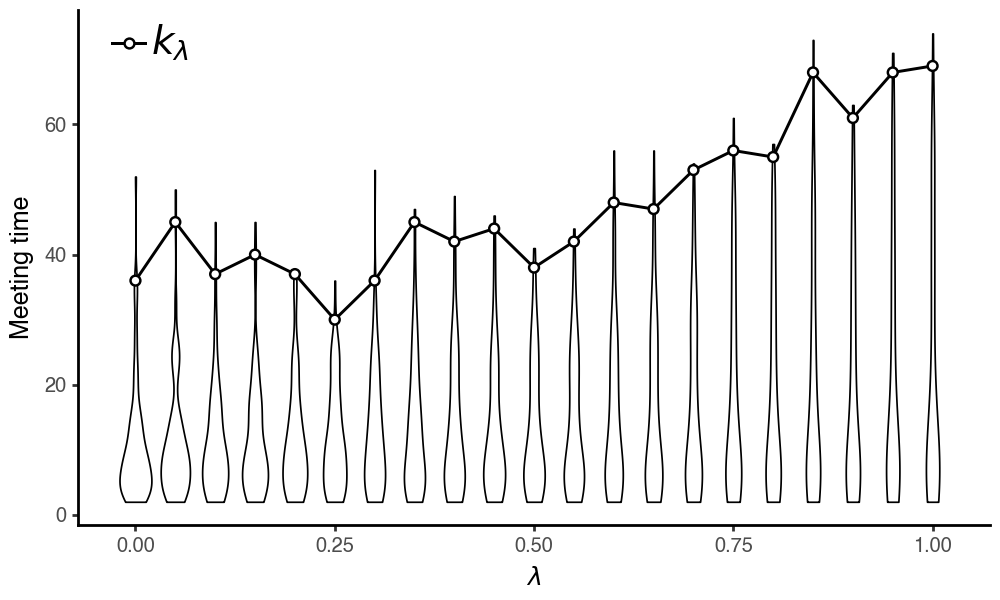

In [12]:
plot_km_grid(mk_grid, lambda_grid)


In [13]:
k_grid = mk_grid["k_grid"]
m_grid = mk_grid["m_grid"]
lag = k_grid

- Now we can estimate the second moment of the UMCMC estimator to estimate the optimal proposal

In [14]:
import cProfile
import io
import pstats
import time

profiler = cProfile.Profile()
start_time = time.perf_counter()
profiler.enable()
try:
    moment_results = estimate_moments(
        key,
        lambda_grid,
        k_grid,
        m_grid,
        mean_init,
        Sigma_init,
        Sigma,
        cholesky_sigma,
        log_target_path,
        grad_log_target_path,
        lag=1,
        nrep=100,
    )
finally:
    profiler.disable()

elapsed_seconds = time.perf_counter() - start_time
profile_output = io.StringIO()
pstats.Stats(profiler, stream=profile_output).strip_dirs().sort_stats("cumtime").print_stats(20)
print(f"estimate_moments elapsed: {elapsed_seconds:.2f} seconds")
print(profile_output.getvalue())

estimating moments:   5%|▍         | 1/21 [00:36<12:15, 36.76s/it]


KeyboardInterrupt: 

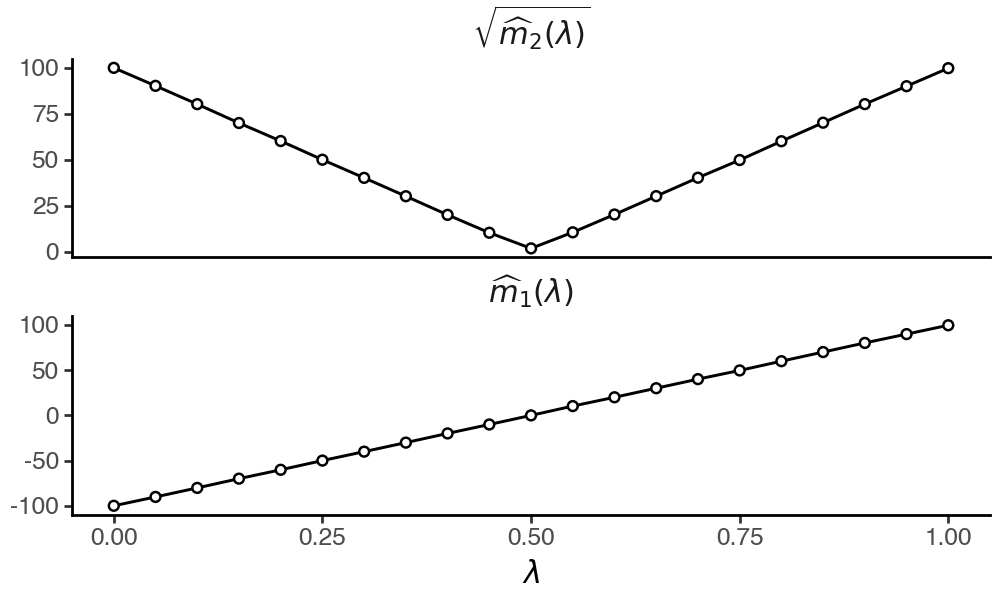

In [15]:
plot_m2_var(moment_results, lambda_grid)

In [16]:
m2 = moment_results["m2"] # to define the optimal proposal for UPS

In [17]:
N_pilot = 100
sigma = estimate_sigma(key, lambda_grid, k_grid, m_grid, lag, mean_init, Sigma_init, Sigma, cholesky_sigma, log_target_path, grad_log_target_path, N_pilot)

In [18]:
M = 100
budget = neyman_allocation(key, lambda_grid, sigma, M)


In [19]:
budget

Array([5, 4, 4, 5, 5, 5, 7, 4, 5, 5, 5, 5, 5, 4, 5, 6, 5, 4, 8, 4], dtype=int32)

In [20]:
ups_result = UPS_estimator(key, lambda_grid, m2, k_grid, m_grid, lag, mean_init, Sigma_init, Sigma, cholesky_sigma, log_target_path, grad_log_target_path, M)

In [21]:
ups_result

(Array(1.0508245, dtype=float32), Array(71980, dtype=int32))

In [22]:
sups_result = SUPS_estimator(key, lambda_grid, budget, k_grid, m_grid, lag, mean_init, Sigma_init, Sigma, cholesky_sigma, log_target_path, grad_log_target_path)

In [23]:
sups_result

(Array(-0.23863077, dtype=float32), Array(72053, dtype=int32))

IS batches: 100%|██████████| 8/8 [00:00<00:00, 15.39it/s]

M_IS=72021 | cout moyen UPS=72007.3 | cout moyen SUPS=72035.2
MSE: {'UPS': np.float64(25.686439447446457), 'SUPS': np.float64(0.12311385070190227), 'IS': np.float64(2394.429854685177)}


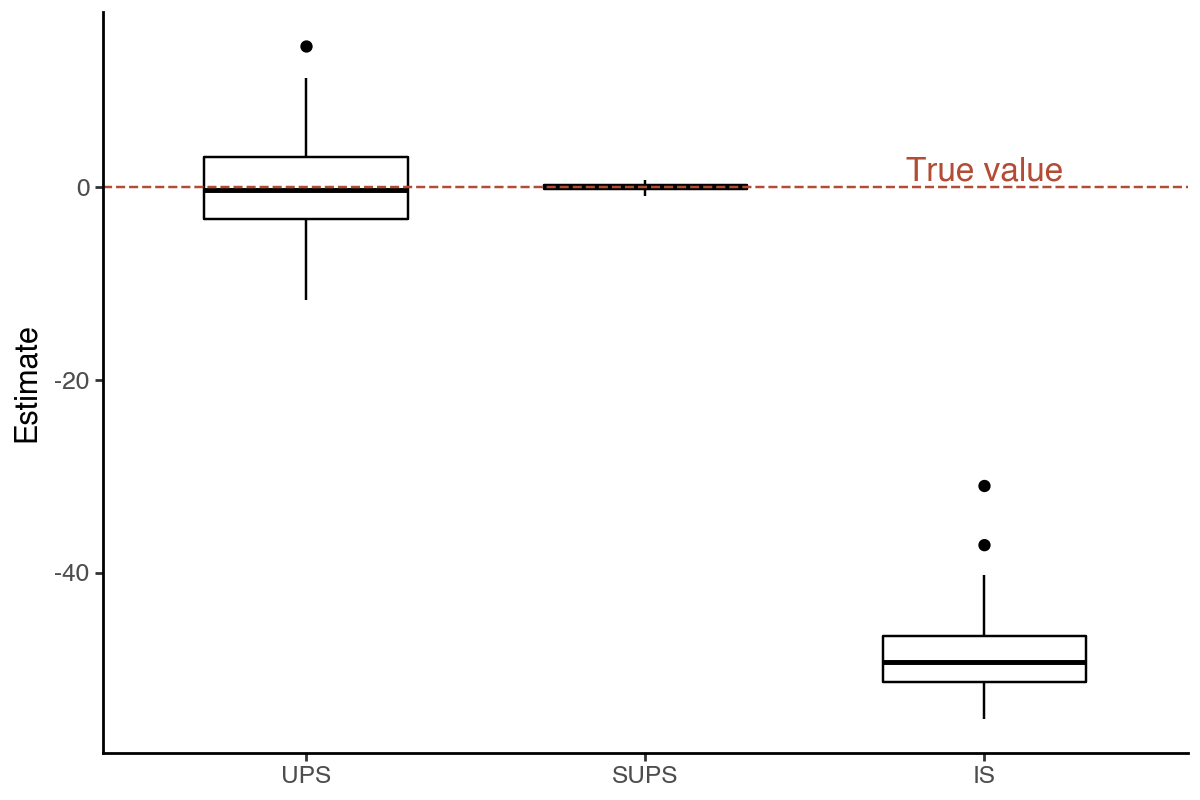

In [24]:
import numpy as np
import pandas as pd
import plotnine as p9
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm
from src.IS_estimator import IS_estimator
from src.UPS_estimator import UPS_estimator
from src.SUPS_estimator import SUPS_estimator

M = 100
nrep = 100
n_workers = 14
true_value = 0.0
key_ups, key_sups, key_is = jax.random.split(key, 3)
ups_keys = jax.random.split(key_ups, nrep)
sups_keys = jax.random.split(key_sups, nrep)
is_keys = jax.random.split(key_is, nrep)


def run_ups(rep_key):
    estimate, cost = UPS_estimator(
        rep_key,
        lambda_grid,
        m2,
        k_grid,
        m_grid,
        lag,
        mean_init,
        Sigma_init,
        Sigma,
        cholesky_sigma,
        log_target_path,
        grad_log_target_path,
        M,
    )
    return float(jax.device_get(estimate)), float(jax.device_get(cost))


def run_sups(rep_key):
    estimate, cost = SUPS_estimator(
        rep_key,
        lambda_grid,
        budget,
        k_grid,
        m_grid,
        lag,
        mean_init,
        Sigma_init,
        Sigma,
        cholesky_sigma,
        log_target_path,
        grad_log_target_path,
    )
    return float(jax.device_get(estimate)), float(jax.device_get(cost))


UPS_results = [None] * nrep
SUPS_results = [None] * nrep
with ThreadPoolExecutor(max_workers=n_workers) as executor:
    future_methods = {}
    for index, rep_key in enumerate(ups_keys):
        future_methods[executor.submit(run_ups, rep_key)] = ("UPS", index)
    for index, rep_key in enumerate(sups_keys):
        future_methods[executor.submit(run_sups, rep_key)] = ("SUPS", index)

    with tqdm(total=nrep, desc="UPS", position=0) as ups_progress, tqdm(
        total=nrep, desc="SUPS", position=1
    ) as sups_progress:
        for future in as_completed(future_methods):
            method, index = future_methods[future]
            result = future.result()
            if method == "UPS":
                UPS_results[index] = result
                ups_progress.update(1)
            else:
                SUPS_results[index] = result
                sups_progress.update(1)

UPS_values = np.asarray([result[0] for result in UPS_results])
UPS_costs = np.asarray([result[1] for result in UPS_results])
SUPS_values = np.asarray([result[0] for result in SUPS_results])
SUPS_costs = np.asarray([result[1] for result in SUPS_results])

M_is = max(1, int(round((UPS_costs.mean() + SUPS_costs.mean()) / 2)))
proposal = lambda sample_key: jax.random.normal(sample_key, shape=(d,))
log_weight = lambda x: log_target1(x, D) - log_target0(x)
is_batch_size = n_workers
IS_batches = []
for start in tqdm(range(0, nrep, is_batch_size), desc="IS batches"):
    batch_keys = is_keys[start : start + is_batch_size]
    batch_values = jax.vmap(
        lambda rep_key: IS_estimator(rep_key, log_weight, proposal, M_is)
    )(batch_keys)
    IS_batches.append(np.asarray(jax.device_get(batch_values), dtype=float))
IS_values = np.concatenate(IS_batches)

comparison_mse = {
    "UPS": np.mean((UPS_values - true_value) ** 2),
    "SUPS": np.mean((SUPS_values - true_value) ** 2),
    "IS": np.mean((IS_values - true_value) ** 2),
}
comparison_results = {
    "UPS_values": UPS_values,
    "UPS_costs": UPS_costs,
    "SUPS_values": SUPS_values,
    "SUPS_costs": SUPS_costs,
    "IS_values": IS_values,
    "M_is": M_is,
    "MSE": comparison_mse,
}
print(f"M_IS={M_is} | cout moyen UPS={UPS_costs.mean():.1f} | cout moyen SUPS={SUPS_costs.mean():.1f}")
print("MSE:", comparison_mse)

plot_data = pd.DataFrame({
    "Estimate": np.concatenate([UPS_values, SUPS_values, IS_values]),
    "Estimator": np.repeat(["UPS", "SUPS", "IS"], nrep),
})
plot_data["Estimator"] = pd.Categorical(
    plot_data["Estimator"],
    categories=["UPS", "SUPS", "IS"],
    ordered=True,
)
true_value_label = pd.DataFrame({
    "Estimator": ["IS"],
    "Estimate": [true_value],
    "label": ["True value"],
})
comparison_plot = (
    p9.ggplot(plot_data, p9.aes(x="Estimator", y="Estimate"))
    + p9.geom_boxplot(width=0.6, fill="white", color="black", size=0.5)
    + p9.geom_hline(
        yintercept=true_value,
        linetype="dashed",
        color="#b44b35",
        size=0.5,
    )
    + p9.geom_text(
        data=true_value_label,
        mapping=p9.aes(x="Estimator", y="Estimate", label="label"),
        inherit_aes=False,
        ha="center",
        va="bottom",
        color="#b44b35",
        size=12,
    )
    + p9.labs(x="", y="Estimate", title=None)
    + p9.theme_classic(base_size=11)
    + p9.theme(figure_size=(6, 4))
)
comparison_plot

d=8: 100%|██████████| 5/5 [6:13:15<00:00, 4479.04s/it]  


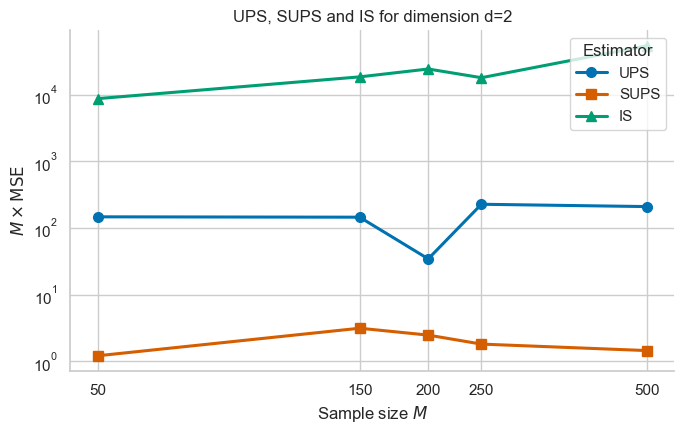

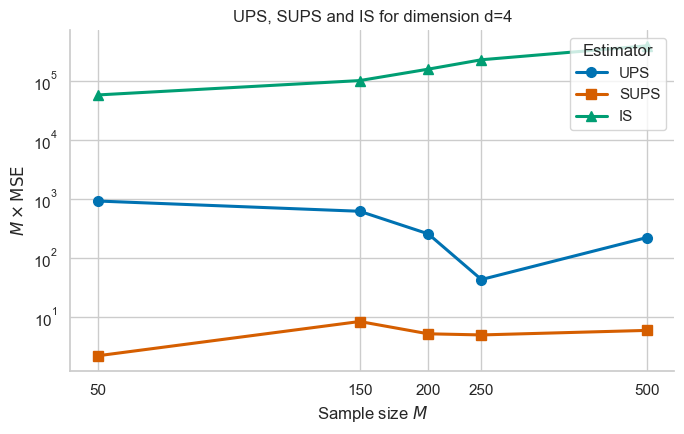

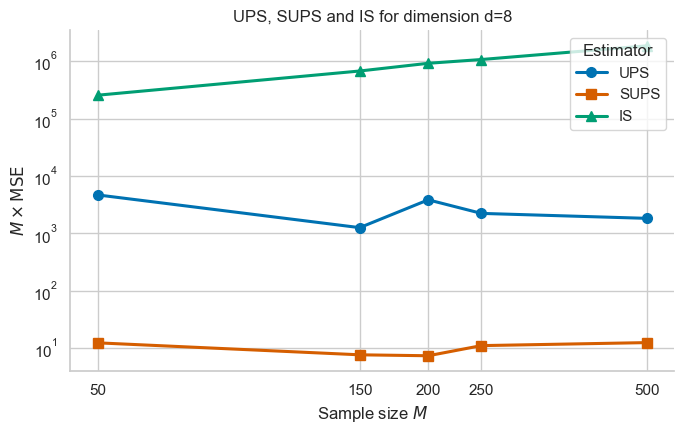

In [ ]:
import jax
import numpy as np
from src.meanshift import inefficiency_plot

key = jax.random.PRNGKey(42)
L = 20
dimensions = [2, 4, 8]
M_values = np.array([50, 150, 200, 250, 500])
lambda_grid = np.linspace(0.0, 1.0, L+1)

inefficiency_results = inefficiency_plot(
    key,
    dimensions,
    M_values,
    lambda_grid,
    alpha=5,
    n_rep_mcmc=5,
    n_rep_is=5,
    n_rep_tuning=20,
    n_rep_moments=10,
    n_pilot=10,
    true_value=0.0,
)

estimating moments: 100%|██████████| 21/21 [07:47<00:00, 22.25s/it]


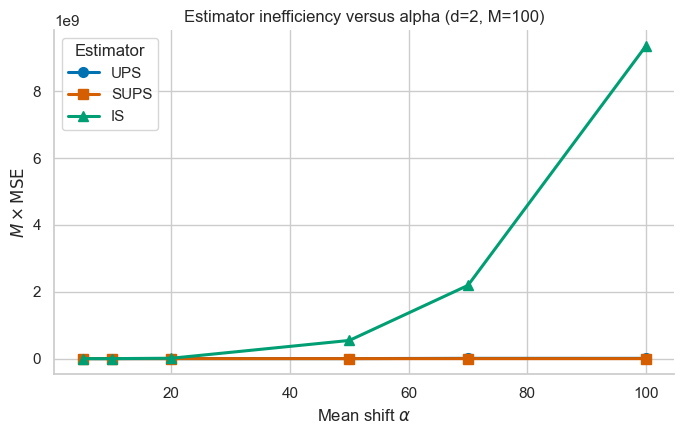

In [6]:

key = jax.random.PRNGKey(42)
alpha_values = np.array([5, 10, 20, 50, 70, 100])
lambda_grid = np.linspace(0.0, 1.0, 21)

alpha_results = inefficiency_vs_alpha(
    key,
    alpha_values,
    dimension=2,
    M=100,
    lambda_grid=lambda_grid,
    n_rep_mcmc=5,
    n_rep_is=5,
    n_rep_tuning=20,
    n_rep_moments=10,
    n_pilot=10,
)

estimating moments: 100%|██████████| 21/21 [02:53<00:00,  8.25s/it]


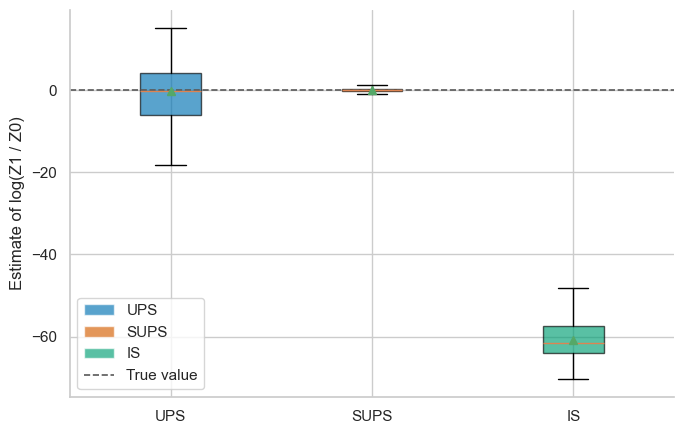

In [3]:
import importlib
import src.meanshift as meanshift_module

meanshift_module = importlib.reload(meanshift_module)

key = jax.random.PRNGKey(42)
boxplot_results = meanshift_module.plot_estimator_boxplot(
    key,
    dimension=2,
    M=50,
    lambda_grid=np.linspace(0.0, 1.0, 21),
    alpha=10,
    n_rep_mcmc=100,
    n_rep_is=100,
    n_rep_tuning=20,
    n_rep_moments=20,
    n_pilot=10,
)

estimating moments: 100%|██████████| 21/21 [02:31<00:00,  7.22s/it]


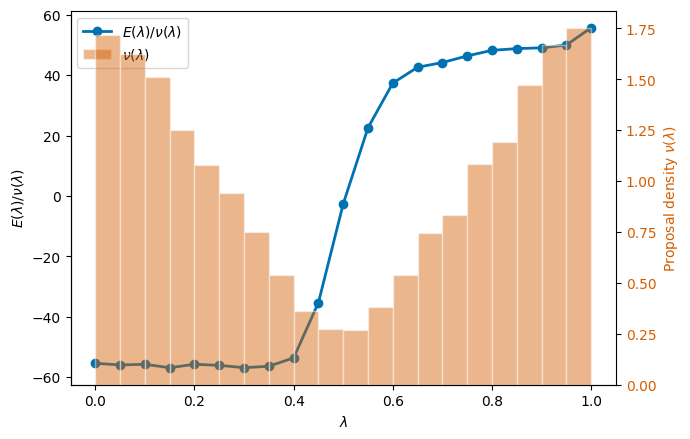

In [3]:
ups_diagnostic = plot_ups_integrand_and_proposal(
    jax.random.PRNGKey(42),
    dimension=2,
    lambda_grid=np.linspace(0.0, 1.0, 21),
    alpha=10,
    n_rep_gridpoint=10,
    n_rep_tuning=20,
    n_rep_moments=20,
    n_proposal_samples = 10000
)

In [ ]:
from scipy.stats import t
from src.meanshift import _g_log_target, _g_grad_log_target


def confidence_interval_mean(estimates, confidence_level=0.95):
    """Student confidence interval for the mean of independent replications."""
    estimates = np.asarray(estimates, dtype=float)

    mean = estimates.mean()
    standard_error = estimates.std(ddof=1) / np.sqrt(estimates.size)
    critical_value = t.ppf(
        (1 + confidence_level) / 2,
        df=estimates.size - 1,
    )
    lower = mean - critical_value * standard_error
    upper = mean + critical_value * standard_error
    return {
        "mean": mean,
        "lower": lower,
        "upper": upper,
        "length": upper - lower,
        "n_rep": estimates.size,
    }


def run_ups_sups_confidence_comparison(
    dimension=2,
    alpha=10,
    n_grid=21,
    n_rep_ups=10,
    n_rep_sups=10,
    ups_budget=1,
    sups_budget=30,
    n_rep_tuning=10,
    n_rep_moments=10,
    n_pilot=10,
):
    """Compute 95% CIs for UPS and SUPS estimates."""
    lambda_grid = jnp.linspace(0.0, 1.0, n_grid)

    key = jax.random.PRNGKey(42)
    key_tuning, key_moments, key_sigma, key_runs = jax.random.split(key, 4)
    Sigma = jnp.eye(dimension)
    cholesky_sigma = jnp.linalg.cholesky(Sigma)
    mean_init = -jnp.ones(dimension)
    Sigma_init = jnp.eye(dimension)
    D = alpha * jnp.ones(dimension)
    log_target_path = lambda x, path: _g_log_target(x, path, D)
    grad_log_target_path = lambda x, path: _g_grad_log_target(x, D)

    tuning = tune_km_grid(
        key_tuning,
        lambda_grid,
        Sigma,
        mean_init,
        Sigma_init,
        log_target_path,
        lag=1,
        nrep=n_rep_tuning,
    )
    k_grid = tuning["k_grid"]
    m_grid = tuning["m_grid"]
    lag = k_grid
    moment_results = estimate_moments(
        key_moments,
        lambda_grid,
        k_grid,
        m_grid,
        mean_init,
        Sigma_init,
        Sigma,
        cholesky_sigma,
        log_target_path,
        grad_log_target_path,
        lag=1,
        nrep=n_rep_moments,
    )
    m2 = moment_results["m2"]
    sigma = estimate_sigma(
        key_sigma,
        lambda_grid,
        k_grid,
        m_grid,
        lag,
        mean_init,
        Sigma_init,
        Sigma,
        log_target_path,
        grad_log_target_path,
        n_pilot,
    )

    scenarios = [
        ("UPS", ups_budget, n_rep_ups),
        ("SUPS", sups_budget, n_rep_sups),
        ("SUPS", sups_budget, n_rep_sups),
    ]
    total_runs = sum(n_reps for _, _, n_reps in scenarios)
    replication_keys = jax.random.split(key_runs, total_runs)
    estimates = {}
    key_index = 0

    for estimator_name, budget, n_reps in scenarios:
        budget_keys = replication_keys[key_index : key_index + n_reps]
        key_index += n_reps
        if estimator_name == "UPS":
            values = [
                UPS_estimator(
                    rep_key,
                    lambda_grid,
                    m2,
                    k_grid,
                    m_grid,
                    lag,
                    mean_init,
                    Sigma_init,
                    Sigma,
                    log_target_path,
                    grad_log_target_path,
                    M=budget,
                )[0]
                for rep_key in budget_keys
            ]
        else:
            values = []
            for rep_key in budget_keys:
                key_allocation, key_estimator = jax.random.split(rep_key)
                allocation = neyman_allocation(
                    key_allocation, lambda_grid, sigma, budget
                )
                values.append(
                    SUPS_estimator(
                        key_estimator,
                        lambda_grid,
                        allocation,
                        k_grid,
                        m_grid,
                        lag,
                        mean_init,
                        Sigma_init,
                        Sigma,
                        log_target_path,
                        grad_log_target_path,
                    )[0]
                )
        estimates[(estimator_name, budget)] = np.asarray(
            [float(jax.device_get(value)) for value in values]
        )

    results = {
        label: {
            **confidence_interval_mean(values),
            "estimates": values,
        }
        for label, values in estimates.items()
    }
    for (estimator_name, budget), result in results.items():
        print(
            f"{estimator_name} (M={budget}): moyenne={result['mean']:.6g}, "
            f"IC 95 %=[{result['lower']:.6g}, {result['upper']:.6g}], "
            f"longueur={result['length']:.6g}, n={result['n_rep']}"
        )
    return results

In [6]:
confidence_results = run_ups_sups_confidence_comparison()

estimating moments: 100%|██████████| 21/21 [01:01<00:00,  2.94s/it]


UPS (M=1): moyenne=-3.37119, IC 95 %=[-40.9167, 34.1743], longueur=75.0911, n=10
SUPS (M=30): moyenne=-0.148172, IC 95 %=[-0.671669, 0.375325], longueur=1.04699, n=10
